# Notes

- Two worlds when building the model:
1. The "small" world: The self-contained logical world of the model, where there are no pure surprises
2. The "large" world: The broader context in which one deploys the world, with events that may not have been imagined in the small world

- You must ensure that the the model's logic is correct in the small world, making sure it performs as expected under favorable assumptions. However, this logical consistency doesn't ensure optimality in the large world, as the model will always be an incomplete representation of the large world.

## 2.1 The Garden of Forking Paths

**Bayesian Inference**: Counting the number of ways things can happen and comparing the possibilities
- **Parameter**: Way of indexing possible explanations of the data (Ex: $p = \text{Proportion of Water on Earth}$)
- **Likelihood**: Number of ways that a specific set of parameters $\theta = (\theta_1, \theta_2, ...)$ can produce the data.
- **Prior Probability**: Prior plausibility distribution of any particular parameter value before looking at data
    - When there is no previous information on the parameter value, use the _principle of indifference_: assign an equal number of ways that each conjecture could be correct, before seeing any data.
- **Posterior Probability**: Updated plausibility distribution AFTER looking at data

## 2.2 Building a Model

3 steps to every Bayesian Model:
1. $\underline{\text{Data Story}}$: Motivate model by narrating how data might arise (set priors).
    - The data story must be complete, in the sense that it is sufficient to specify an algorithm for simulating new data.
2. $\underline{\text{Update}}$: Educate your statistical model by feeding it data.
    - The model takes the prior probabilities, calculates the "number" of ways observed data happens given prior probabilities, then updates relative plausibility based on what can happen.
    - Every updates set of plausibilities becomes the initial plausibilities for the next observations; hence, every conclusion is the starting point for future inference.
3. $\underline{\text{Evaluate}}$: Supervise the model, seeing it how it performed and revising if necessary.
    - Check calculations and be cautious of any potential differences between the model and reality.
    - Two points of caution:
        1. Model's certainty is no guarantee it is a good one; if the assumptions of the model don't reflect reality, the model's output won't either.
        2. Supervise and critique your model's results; check performance related to aspects of data it may not know about.


Example [Globe Tossing Model]:
- Data Story: The proportion of Earth covered by water is $p$. A single toss of the glove has a probability $p$ of producing a Water (W) observation and $1 - p$ of a Land (L) Observation. Each toss of the globe is indepdent from others:
- Update: We start with a prior for $p$ of $Uniform(0,1)$. We toss the globe and observe a Water (W) observation. The probabilities of p are updated such that $p = 0$ is now impossible and $p > 0.5$ is now more likely.
- Evaluate: Examine the globe - does it seem as though there is more water than land? If so, we are likely doing well. Regardless, more data is necessary to get closer to the truth.

## 2.3 Components of a Model

- **Variables**: Symbols taking on different values
    - _Observed_ variables: The data we see
    - _Unobserved_ variables (parameters): The things we wish to infer
- **Definitions**: Explanations for each of the variables
    - _Observed_ variables: Define a likelihood of occurrence given the unobserved variables
        - Ex (Globe Tossing): $P(W, L|p) = \frac{(W + L)!}{W!L!}p^W(1-p)^L \sim Binomial(p)$
    - _Unobserved_ variables: Define a distribution of prior plausibility:
        - Ex (Globe Tossing): $P(p) = \frac{1}{1 - 0} = 1\sim Uniform(0,1)$
        - Can create it based on the analyst's personal beliefs

## 2.4 Making the Model Go

- You utilize the variables, definitions, and the data to compute the posterior probability of the parameters using Bayes' Theorem:
$$ 
P(\text{prior}|\text{data}) = \frac{P(\text{data}|\text{prior})P(\text{prior})}{P(data)} = \frac{P(\text{data}|\text{prior})P(\text{prior})}{\int_\Omega P(\text{data}|\text{prior})P(\text{prior})d\text{prior}} 
$$

- While the posterior will often be unique, it may not be able to be easily computed. In that case, you must approximate the posterior numerically. 3 ways to do so are:
1. **Grid Approxmiation**: Utilize a finite grid of parameter values throughout the range of the parameters
    - Determine which values will consitute your grid
    - Compute the prior probability at each grid value.
    - Compute the likelihood of each value.
    - Get the unstandardized posterior at each value by multiplying the prior by the likelihood.
    - Get the standardized posterior by dividing each unstandardized value by the sum of the unstandardied values.
2. **Quadratic Approximation**: Take advantage of the fact that the region near the mean posterior of the distribution is almost always nearly Gaussian, the log of a Gaussian is a parabola, and a Gaussian can be described fully by its mean and variance; Useful when there are multiple parameters and the grid becomes too large to reasonably compute/
    - Find the posterior mode thorugh some optimization algorithm.
    - Estimate the curvature of the distribution near the peak.
3. **Markov Chain Monte Carlo**: Pull samples from the posterior rather that provide you a collection of parameter values. Useful for complex models (such as mixed effects models) where grid approximation or quadratic approximation is unsatisfactory. Useful when there is no single, unified function for the posterior.

# Practice Problems

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2M1

In [10]:
potential_p_values = np.linspace(0, 1, 100)

### 1. X = (W,W,W)

We know that $\pi(p) = 1, p \in [0, 1]$. We also know that $\mathbb{P}(X|p) = \begin{cases}p & X = W \\ 1 - p & X = L\end{cases}$.
Therefore, using Bayes' Theorem:
$$
\mathbb{P}(p|W, W, W) = \frac{\mathbb{P}(W, W, W|p)\pi(p)}{\mathbb{P}(W, W, W)} = \frac{p^3 * 1}{\int_0^1 p^3 * 1 dp} = \frac{p^3}{\frac{1}{4}p^4\bigg|_0^1} = 4p^3, p \in (0, 1]
$$


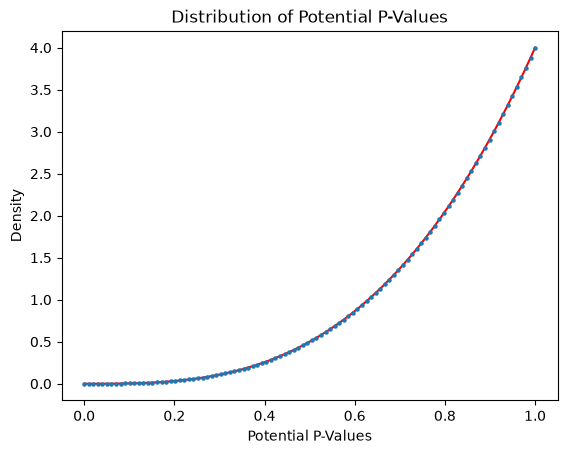

In [9]:
plt.scatter(potential_p_values, 4 * potential_p_values**3, s = 5, zorder = 2)
plt.plot(potential_p_values, 4 * potential_p_values**3, color = 'red', zorder = 1)
plt.xlabel('Potential P-Values')
plt.ylabel('Density')
plt.title('Distribution of Potential P-Values')
plt.show()

### 2. X = (W, W, W, L)

Using the same prior and conditional probability as before:
$$
\mathbb{P}(p|W, W, W, L) = \frac{\mathbb{P}(W, W, W, L|p)\pi(p)}{\mathbb{P}(W, W, W, L)} = \frac{p^3 * (1  - p) * 1}{\int_0^1(p^3 * (1 - p))dp}
\\= \frac{p^3 * (1 - p)}{\int_0^1(p^3 - p^4)dp} = \frac{p^3 * (1 - p)}{\bigg[\frac{1}{4}p^4 - \frac{1}{5}p^5\bigg]_0^1} = 20* p^3 * (1 - p), p \in (0, 1)
$$

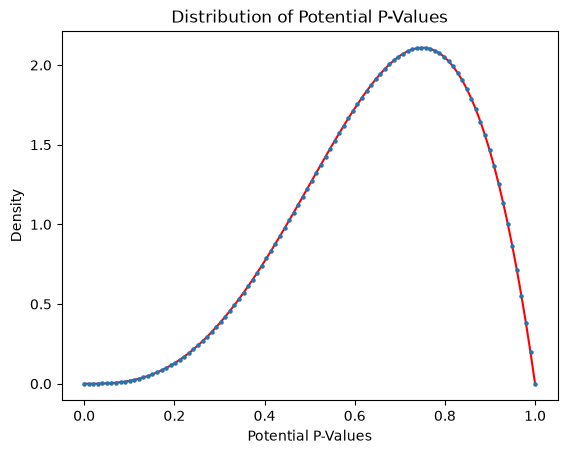

In [12]:
plt.scatter(potential_p_values, 20 * potential_p_values**3 * (1 - potential_p_values), s = 5, zorder = 2)
plt.plot(potential_p_values, 20 * potential_p_values**3 * (1 - potential_p_values), color = 'red', zorder = 1)
plt.xlabel('Potential P-Values')
plt.ylabel('Density')
plt.title('Distribution of Potential P-Values')
plt.show()

### 3. X = (L, W, W, L, W, W, W)

$$
\mathbb{P}(p|L, W, W, L, W, W, W) = \frac{\mathbb{P}(L, W, W, L, W, W, W|p)\pi(p)}{\mathbb{P}(L, W, W, L, W, W, W)} = \frac{p^5 * (1  - p)^2 * 1}{\int_0^1(p^5 * (1 - p)^2)dp}
\\= \frac{p^5 * (1 - p)^2}{\int_0^1(p^5 * (1 - p)^2)dp} = \frac{p^5 * (1 - p)^2}{\int_0^1(p^5 - 2p^6 + p^7)dp} 
\\ = \frac{p^5 * (1 - p)^2}{\bigg[\frac{1}{6}p^6 - \frac{2}{7}p^7 + \frac{1}{8}p^8\bigg]_0^1} = 168 * p^5 * (1 - p)^2, p \in (0, 1)
$$

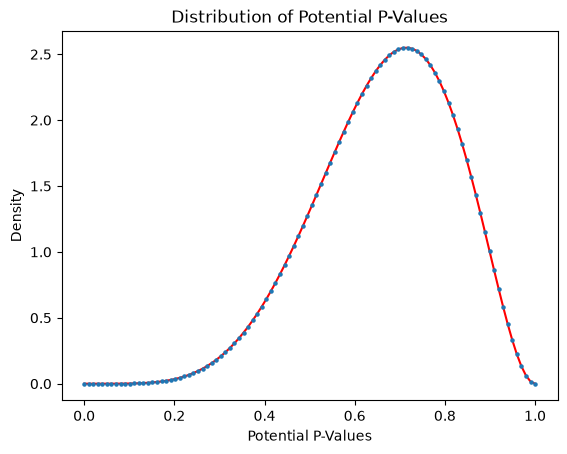

In [19]:
plt.scatter(potential_p_values, 168 * potential_p_values**5 * (1 - potential_p_values)**2, s = 5, zorder = 2)
plt.plot(potential_p_values, 168 * potential_p_values**5 * (1 - potential_p_values)**2, color = 'red', zorder = 1)
plt.xlabel('Potential P-Values')
plt.ylabel('Density')
plt.title('Distribution of Potential P-Values')
plt.show()

## 2M2

We have a new prior now: $\pi(p) = \begin{cases}0 & p < .5 \\ 2 & p \geq .5\end{cases}$. Now, we modify the calculations for each of the sets of observations in 2M1:

### 1. X = (W,W,W)

$$
\mathbb{P}(p|W, W, W) = \frac{\mathbb{P}(W, W, W|p)\pi(p)}{\mathbb{P}(W, W, W)} = \frac{p^3 * 2}{\int_{0.5}^1 p^3 * 2 dp} = \frac{p^3}{\frac{1}{4}p^4\bigg|_{0.5}^1}\\
\frac{p^3}{\frac{1}{4} - \frac{0.5^4}{4}} = \frac{64}{15}p^3, p \in [0.5, 1]
$$

### 2. X = (W, W, W, L)

$$
\mathbb{P}(p|W, W, W, L) = \frac{\mathbb{P}(W, W, W, L|p)\pi(p)}{\mathbb{P}(W, W, W, L)} = \frac{p^3 * (1  - p) * 2}{\int_{0.5}^1(p^3 * (1 - p) * 2)dp}
\\= \frac{p^3 * (1 - p)}{\int_{0.5}^1(p^3 - p^4)dp} = \frac{p^3 * (1 - p)}{\bigg[\frac{1}{4}p^4 - \frac{1}{5}p^5\bigg]_{0.5}^1}\\
= \frac{p^3 * (1 - p)}{\frac{1}{4} - \frac{1}{5} - \frac{0.5^4}{4} + \frac{0.5^5}{5}} = \frac{320}{13} * p^3 * (1 - p), p \in [0.5, 1)
$$

### 3. X = (L, W, W, L, W, W, W)

$$
\mathbb{P}(p|L, W, W, L, W, W, W) = \frac{\mathbb{P}(L, W, W, L, W, W, W|p)\pi(p)}{\mathbb{P}(L, W, W, L, W, W, W)} = \frac{p^5 * (1  - p)^2 * 2}{\int_{0.5}^1(p^5 * (1 - p)^2) * 2dp}
\\= \frac{p^5 * (1 - p)^2}{\int_{0.5}^1(p^5 * (1 - p)^2)dp} = \frac{p^5 * (1 - p)^2}{\int_{0.5}^1(p^5 - 2p^6 + p^7)dp} 
\\ = \frac{p^5 * (1 - p)^2}{\bigg[\frac{1}{6}p^6 - \frac{2}{7}p^7 + \frac{1}{8}p^8\bigg]_{0.5}^1}
\\ = \frac{p^5 * (1 - p)^2}{\frac{1}{6} - \frac{2}{7} + \frac{1}{8} - \frac{0.5^6}{6} + \frac{2 * 0.5^7}{7} - \frac{0.5^8}{8}} \approx 196.38 * p^5 * (1 - p)^2, p \in [0.5, 1)
$$

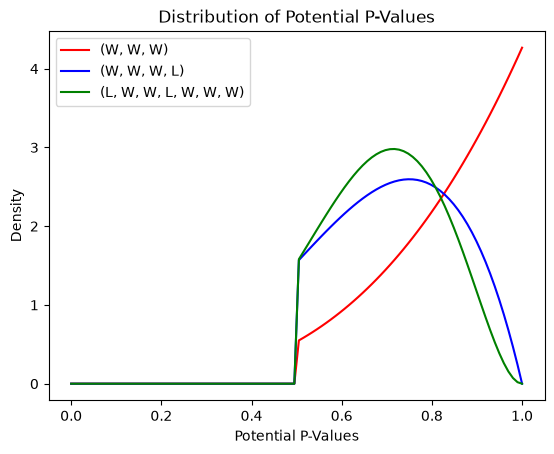

In [29]:
plt.plot(potential_p_values, np.where(potential_p_values >= 0.5, 64/15 * potential_p_values**3, 0), color = 'red', zorder = 1, label = '(W, W, W)')
plt.plot(potential_p_values, np.where(potential_p_values >= 0.5, 320/13 * potential_p_values**3 * (1 - potential_p_values), 0), color = 'blue', zorder = 1, label = '(W, W, W, L)')
plt.plot(potential_p_values, np.where(potential_p_values >= 0.5, 196.38 * potential_p_values**5 * (1 - potential_p_values)**2, 0), color = 'green', zorder = 1, label = '(L, W, W, L, W, W, W)')
plt.xlabel('Potential P-Values')
plt.ylabel('Density')
plt.title('Distribution of Potential P-Values')
plt.legend()
plt.show()